In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scanpy as sc 
import gseapy as gp

In [2]:
from matplotlib import rcParams
rcParams['figure.figsize'] = (5, 5)
rcParams["font.family"] = "sans-serif"
rcParams["font.sans-serif"] = ["Arial"]
rcParams["pdf.fonttype"] = 42
rcParams["ps.fonttype"] = 42
sc.set_figure_params(vector_friendly=True, dpi=96, dpi_save=300)

In [3]:
# --- Configuration Constants ---
LFC_CUTOFF = 0.5  # Log2 fold-change threshold for marker genes
PVAL_CUTOFF = 0.05  # Adjusted p-value threshold for marker genes
GENE_SET_LIBRARY = "GO_Biological_Process_2021"  # Gene set library from Enrichr
np.random.seed(2025)
baselines = [
    "Seurat",
    "SpatialPrompt",
    "SpaGCN",
    "DeepGTF",
    "BayesSpace",
    "BASS",
    "SR-DGN",
    "STAGATE",
    "GraphST",
    "CadaST",
]

In [ ]:
def get_marker_genes(adata, cluster_key, lfc_cutoff=LFC_CUTOFF, pval_cutoff=PVAL_CUTOFF):
    try:
        sc.tl.rank_genes_groups(adata, groupby=cluster_key, method="wilcoxon", use_raw=False)
    except Exception as e:
        print(f"Error running rank_genes_groups for {cluster_key}: {e}")
        return {}

    marker_genes = {}
    unique_clusters = adata.obs[cluster_key].astype(str).unique()
    for cluster in unique_clusters:
        df = sc.get.rank_genes_groups_df(adata, group=cluster)
        significant_markers = df[(df["logfoldchanges"] > lfc_cutoff) & (df["pvals_adj"] < pval_cutoff)]
        marker_genes[cluster] = significant_markers["names"].tolist()
    return marker_genes


def map_clusters(adata, predicted_key, ground_truth_key):
    mapping = {}
    predicted_clusters = adata.obs[predicted_key].unique()

    ground_truth_clusters = adata.obs[ground_truth_key].unique()

    for pred_cluster in predicted_clusters:
        pred_spots = set(adata.obs.index[adata.obs[predicted_key] == pred_cluster])
        best_match = None
        max_jaccard = -1
        for true_cluster in ground_truth_clusters:
            true_spots = set(adata.obs.index[adata.obs[ground_truth_key] == true_cluster])
            j_index = (
                len(pred_spots.intersection(true_spots)) / len(pred_spots.union(true_spots))
                if len(pred_spots.union(true_spots)) > 0
                else 0
            )
            if j_index > max_jaccard:
                max_jaccard = j_index
                best_match = true_cluster
        mapping[pred_cluster] = best_match

    return mapping


def get_enriched_go_terms(gene_list):
    import time 
    time.sleep(10)
    if not gene_list:
        return set()
    try:
        enr = gp.enrichr(
            gene_list=gene_list,
            gene_sets=[GENE_SET_LIBRARY],
            organism="Human",
            outdir=None,
            cutoff=0.05,
        )
        if enr.results is not None and not enr.results.empty:
            return set(enr.results["Term"])  # type:ignore
        else:
            return set()
    except Exception as e:
        print(f"Warning: GO enrichment failed. {e}")
        return set()


def jaccard_similarity(set1, set2):
    """Calculates Jaccard similarity for two sets."""
    if not set1 or not set2:
        return 0.0

    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    return intersection / union


In [5]:
evaluation_artifacts = {}
ground_truth_key = "Annotation"
adata = sc.read_h5ad("benchmark.h5ad")
adata.var_names_make_unique()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 3611 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'bayesSpace', 'graphst', 'leiden', 'louvain', 'spaGCN', 'stagate', 'stcada', 'truth', 'Annotation', 'Seurat', 'stLearn', 'SpaGCN', 'BayesSpace', 'DeepST', 'STAGATE', 'STcada', 'DRSC', 'GraphST', 'STcada_rep', 'BASS', 'cadaST', 'CadaST', 'DeepGTF', 'SpatialPrompt', 'SR-DGN', 'SpatialPrompt_ro', 'SR-DGN_ro', 'tmp'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Annotation_colors', 'BASS_colors', 'BayesSpace_colors', 'CadaST_colors', 'DRSC_colors', 'DeepGTF_colors', 'DeepST_colors', 'GraphST_colors', 'SR-DGN_colors', 'SR-DGN_ro_colors', 'STAGATE_colors', 'STcada_colors', 'STcada_rep_colors', 'Seurat_colors', 'SpaGCN_colors', 'SpatialPrompt_colors', 'SpatialPrompt_ro_colors', 'bayesSpace_colors', 'graphst_colors', 'leiden_colors', 'louvain_colors', 'spaGCN_colors', 'spatial', 'stLearn_colors', 'stagate_colors', 'stcada_colors', 'tmp_colors', 'truth_colors', 'log1p'
    obsm: 'spatial'

/tmp/ipykernel_40085/776174456.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=ground_truth_key, palette = 'tab10')


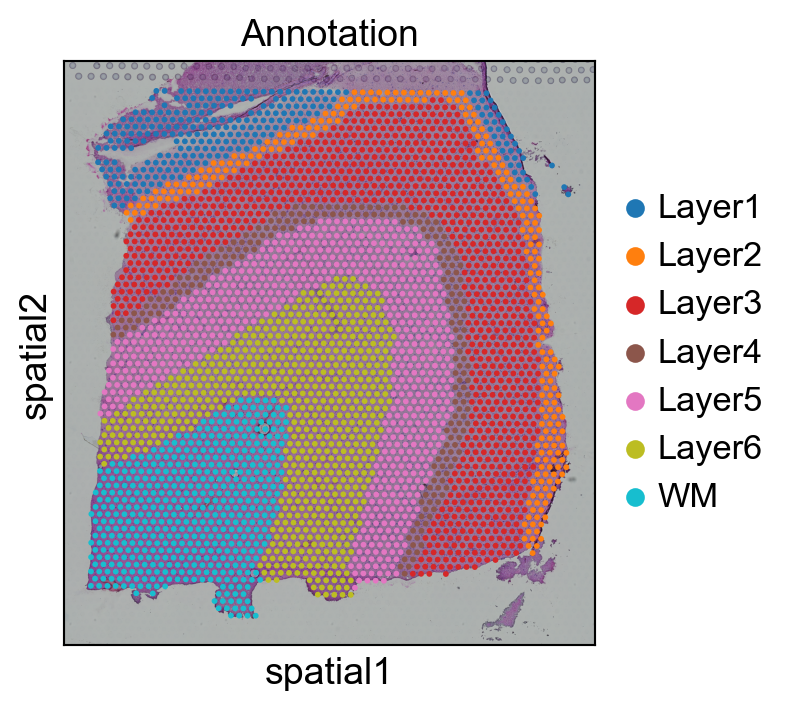

/tmp/ipykernel_40085/776174456.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color=baselines, palette = 'tab10', ncols = len(baselines) // 2, legend_loc = 'none')


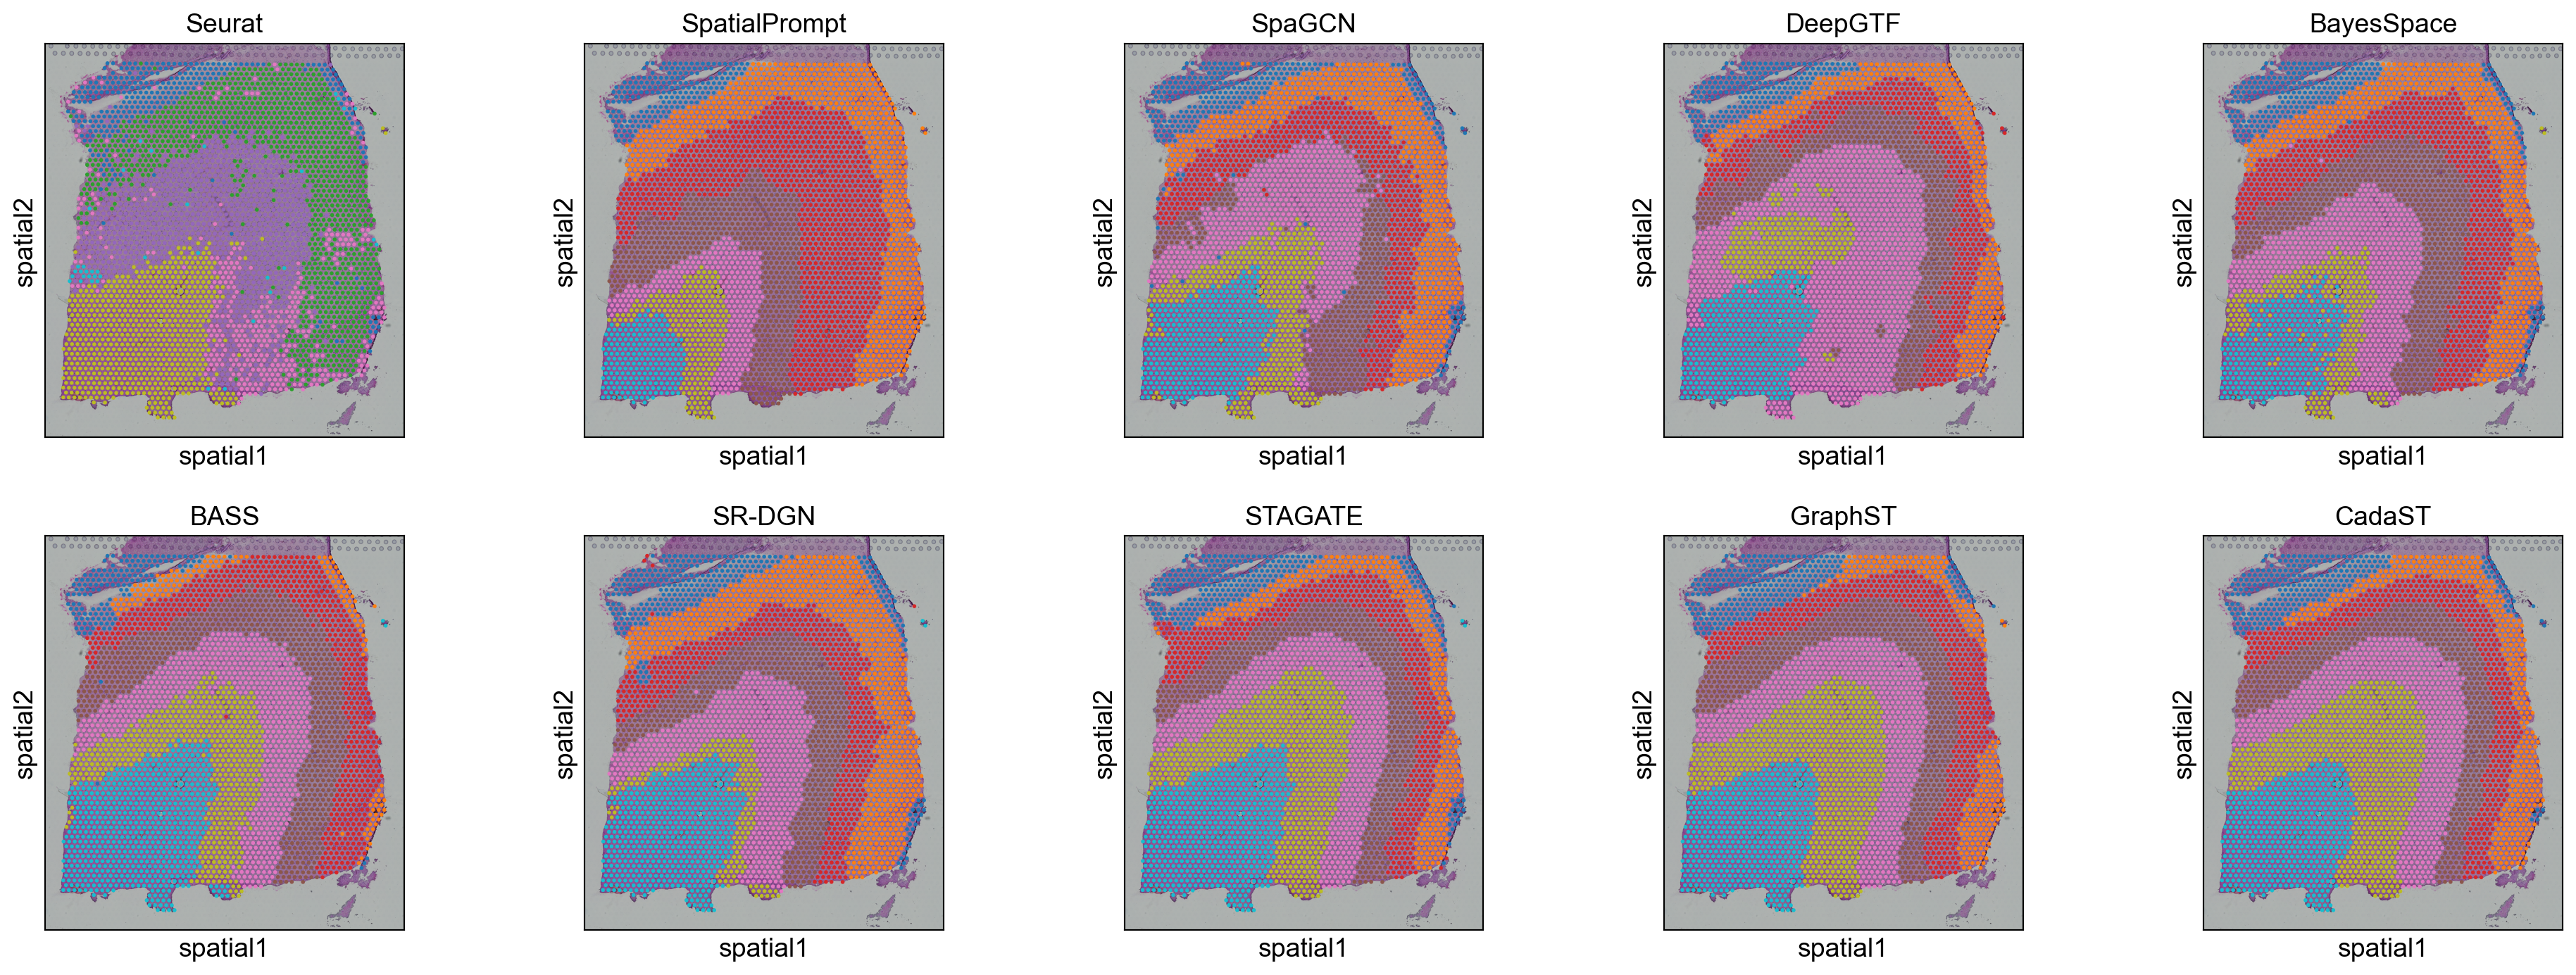

In [6]:
sc.pl.spatial(adata, color=ground_truth_key, palette = 'tab10')
sc.pl.spatial(adata, color=baselines, palette = 'tab10', ncols = len(baselines) // 2, legend_loc = 'none')

In [7]:
ground_truth_markers = get_marker_genes(adata.copy(), ground_truth_key)
ground_truth_go_terms = {cluster: get_enriched_go_terms(genes) for cluster, genes in ground_truth_markers.items()}
print(f"Found ground truth marker sets for {len(ground_truth_markers)} clusters.")
evaluation_artifacts[ground_truth_key] = {"marker_genes": ground_truth_markers, "go_terms": ground_truth_go_terms}
results_data = []
for method_key in baselines:
    mapping = map_clusters(adata, method_key, ground_truth_key)
    print(f"Mapped {len(mapping)} predicted clusters to ground truth layers.")
    print(mapping)

    predicted_markers = get_marker_genes(adata.copy(), method_key)
    predicted_go_terms = {cluster: get_enriched_go_terms(genes) for cluster, genes in predicted_markers.items()}
    print(f"Found predicted marker sets for {len(predicted_markers)} clusters.")
    evaluation_artifacts[method_key] = {"marker_genes": predicted_markers, "go_terms": predicted_go_terms}

    gene_scores, go_scores = [], []

    for pred_cluster, true_cluster in mapping.items():
        # if pred_cluster in predicted_markers and true_cluster in ground_truth_markers:
        pred_genes = set(predicted_markers[str(pred_cluster)])
        true_genes = set(ground_truth_markers[true_cluster])
        gene_jaccard = jaccard_similarity(pred_genes, true_genes)
        gene_scores.append(gene_jaccard)

        pred_go = predicted_go_terms.get(str(pred_cluster), set())
        true_go = ground_truth_go_terms.get(true_cluster, set())
        go_jaccard = jaccard_similarity(pred_go, true_go)
        go_scores.append(go_jaccard)

    if gene_scores and go_scores:
        results_data.append(
            {
                "Method": method_key,
                "Marker Jaccard": gene_scores,
                "Go Term Jaccard": go_scores,
                "Mean Marker Jaccard": np.mean(gene_scores),
                "Mean GO Term Jaccard": np.mean(go_scores),
            }
        )


Found ground truth marker sets for 7 clusters.
Mapped 6 predicted clusters to ground truth layers.
{2: 'Layer3', 1: 'Layer1', 5: 'WM', 6: 'Layer6', 3: 'Layer5', 4: 'Layer5'}
Found predicted marker sets for 6 clusters.
Mapped 7 predicted clusters to ground truth layers.
{2: 'Layer5', 4: 'Layer1', 6: 'WM', 0: 'Layer6', 3: 'Layer6', 1: 'WM', 5: 'Layer3'}
Found predicted marker sets for 7 clusters.
Mapped 7 predicted clusters to ground truth layers.
{3: 'Layer3', 1: 'Layer1', 7: 'WM', 2: 'Layer3', 5: 'Layer5', 6: 'Layer6', 4: 'Layer5'}
Found predicted marker sets for 7 clusters.
Mapped 7 predicted clusters to ground truth layers.
{7: 'Layer3', 5: 'Layer1', 4: 'WM', 2: 'Layer5', 6: 'Layer2', 3: 'Layer6', 1: 'Layer4'}
Found predicted marker sets for 7 clusters.
Mapped 7 predicted clusters to ground truth layers.
{3: 'Layer3', 1: 'Layer1', 7: 'WM', 5: 'Layer6', 6: 'WM', 2: 'Layer2', 4: 'Layer5'}
Found predicted marker sets for 7 clusters.
Mapped 7 predicted clusters to ground truth layers.
{3

In [8]:
results_df = pd.DataFrame(results_data)
print (results_df)

          Method                                     Marker Jaccard  \
0         Seurat  [0.4951219512195122, 0.6666666666666666, 0.865...   
1  SpatialPrompt  [0.2891125343092406, 0.6666666666666666, 0.734...   
2         SpaGCN  [0.2962962962962963, 0.9285714285714286, 0.921...   
3        DeepGTF  [0.40561797752808987, 0.8571428571428571, 0.93...   
4     BayesSpace  [0.3746130030959752, 1.0, 0.8972055888223552, ...   
5           BASS  [0.36133333333333334, 0.2, 0.8859198355601233,...   
6         SR-DGN  [0.43306010928961747, 0.7777777777777778, 0.93...   
7        STAGATE  [0.32060185185185186, 0.8235294117647058, 0.90...   
8        GraphST  [0.5126705653021443, 0.7142857142857143, 0.949...   
9         CadaST  [0.3986562150055991, 0.9285714285714286, 0.941...   

                                     Go Term Jaccard  Mean Marker Jaccard  \
0  [0.7477707006369426, 0.47706422018348627, 0.92...             0.413722   
1  [0.59206106870229, 0.7239263803680982, 0.86778...            

/tmp/ipykernel_40085/2064302695.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plt_data, x="Method", y="Marker Jaccard", palette="Set3", errorbar="se",)


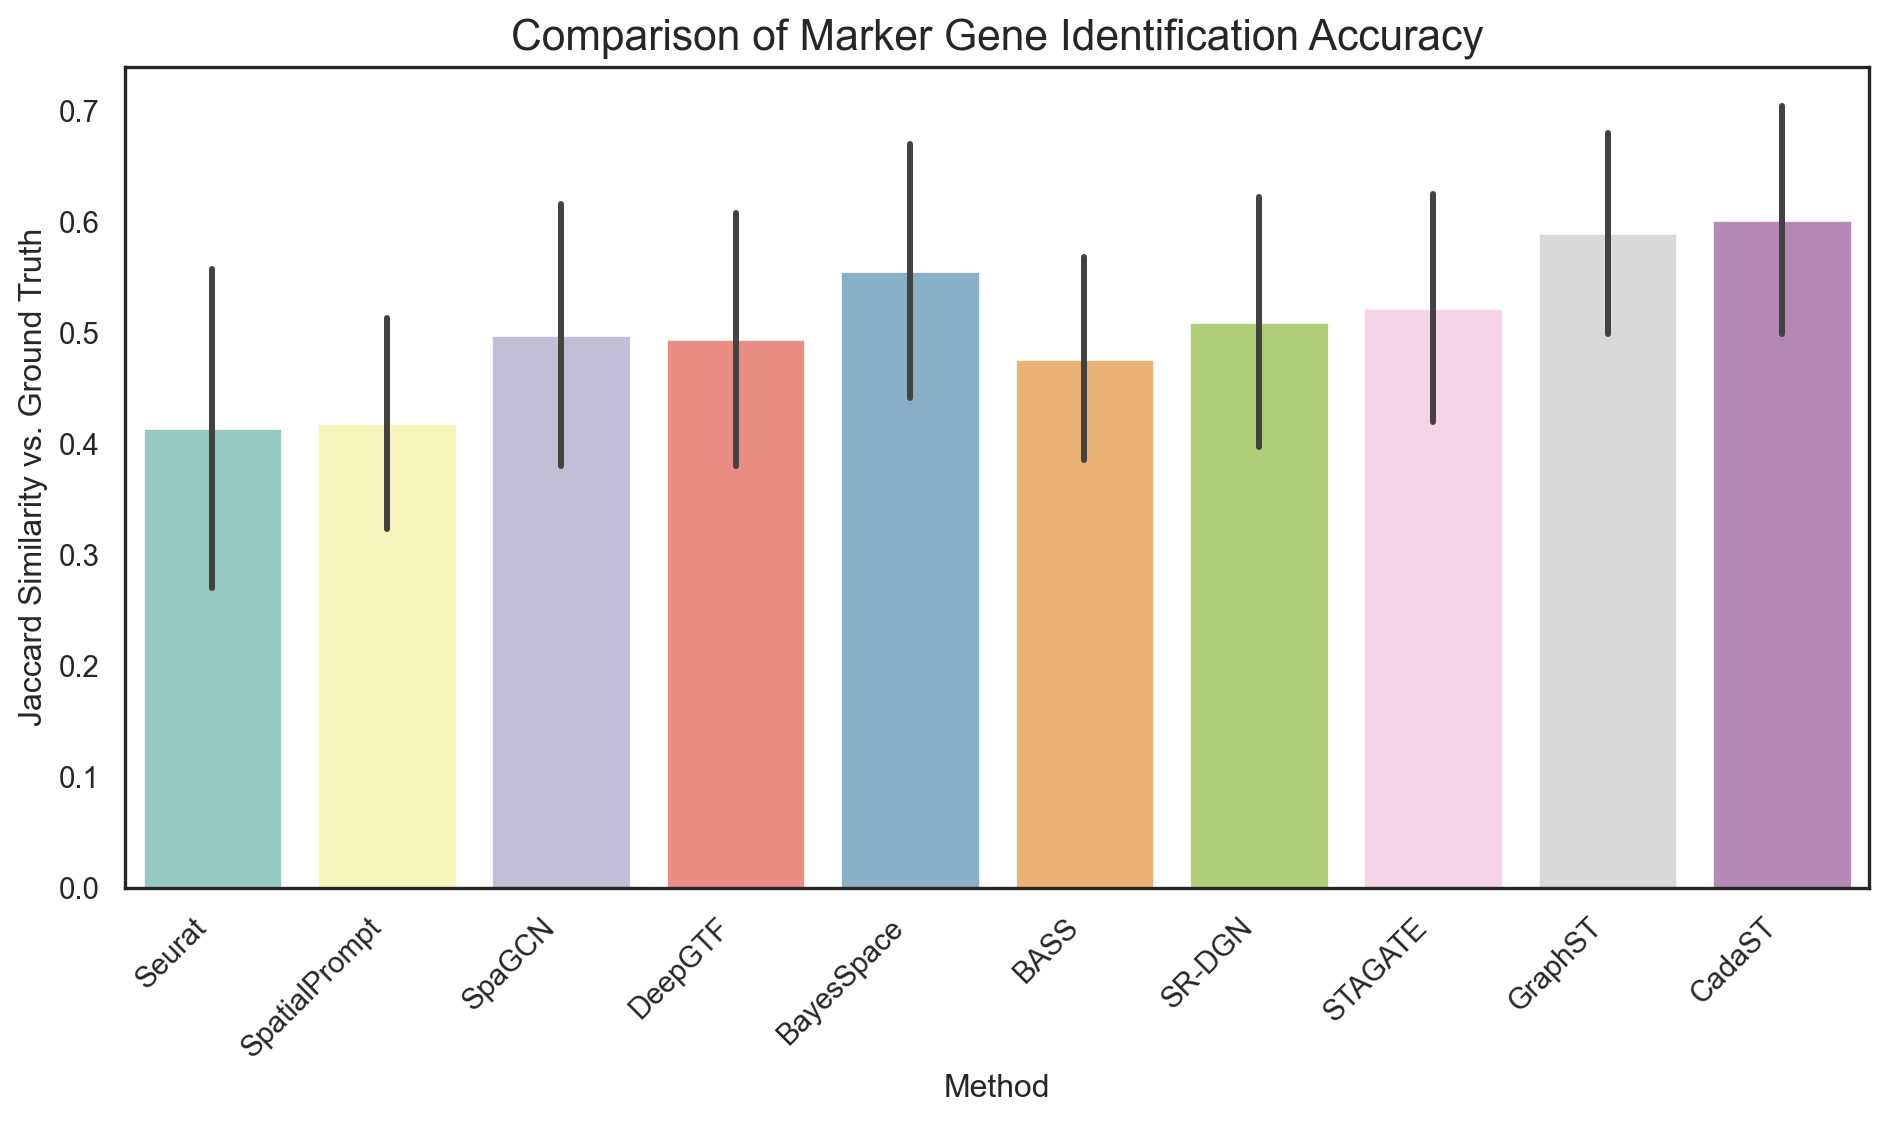

In [16]:
sns.set_theme(style="white")
plt.figure(figsize=(10, 6))
plt_data = results_df[["Method", "Marker Jaccard"]]
plt_data = plt_data.explode("Marker Jaccard")
sns.barplot(data=plt_data, x="Method", y="Marker Jaccard", palette="Set3", errorbar="se",)
plt.title("Comparison of Marker Gene Identification Accuracy", fontsize=16)
plt.ylabel("Jaccard Similarity vs. Ground Truth", fontsize=12)
plt.xlabel("Method", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("marker_jaccard_comparison.pdf", dpi=300, bbox_inches='tight')

/tmp/ipykernel_40085/277244445.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plt_data, x="Method", y="Go Term Jaccard", palette="Set3", errorbar="se")


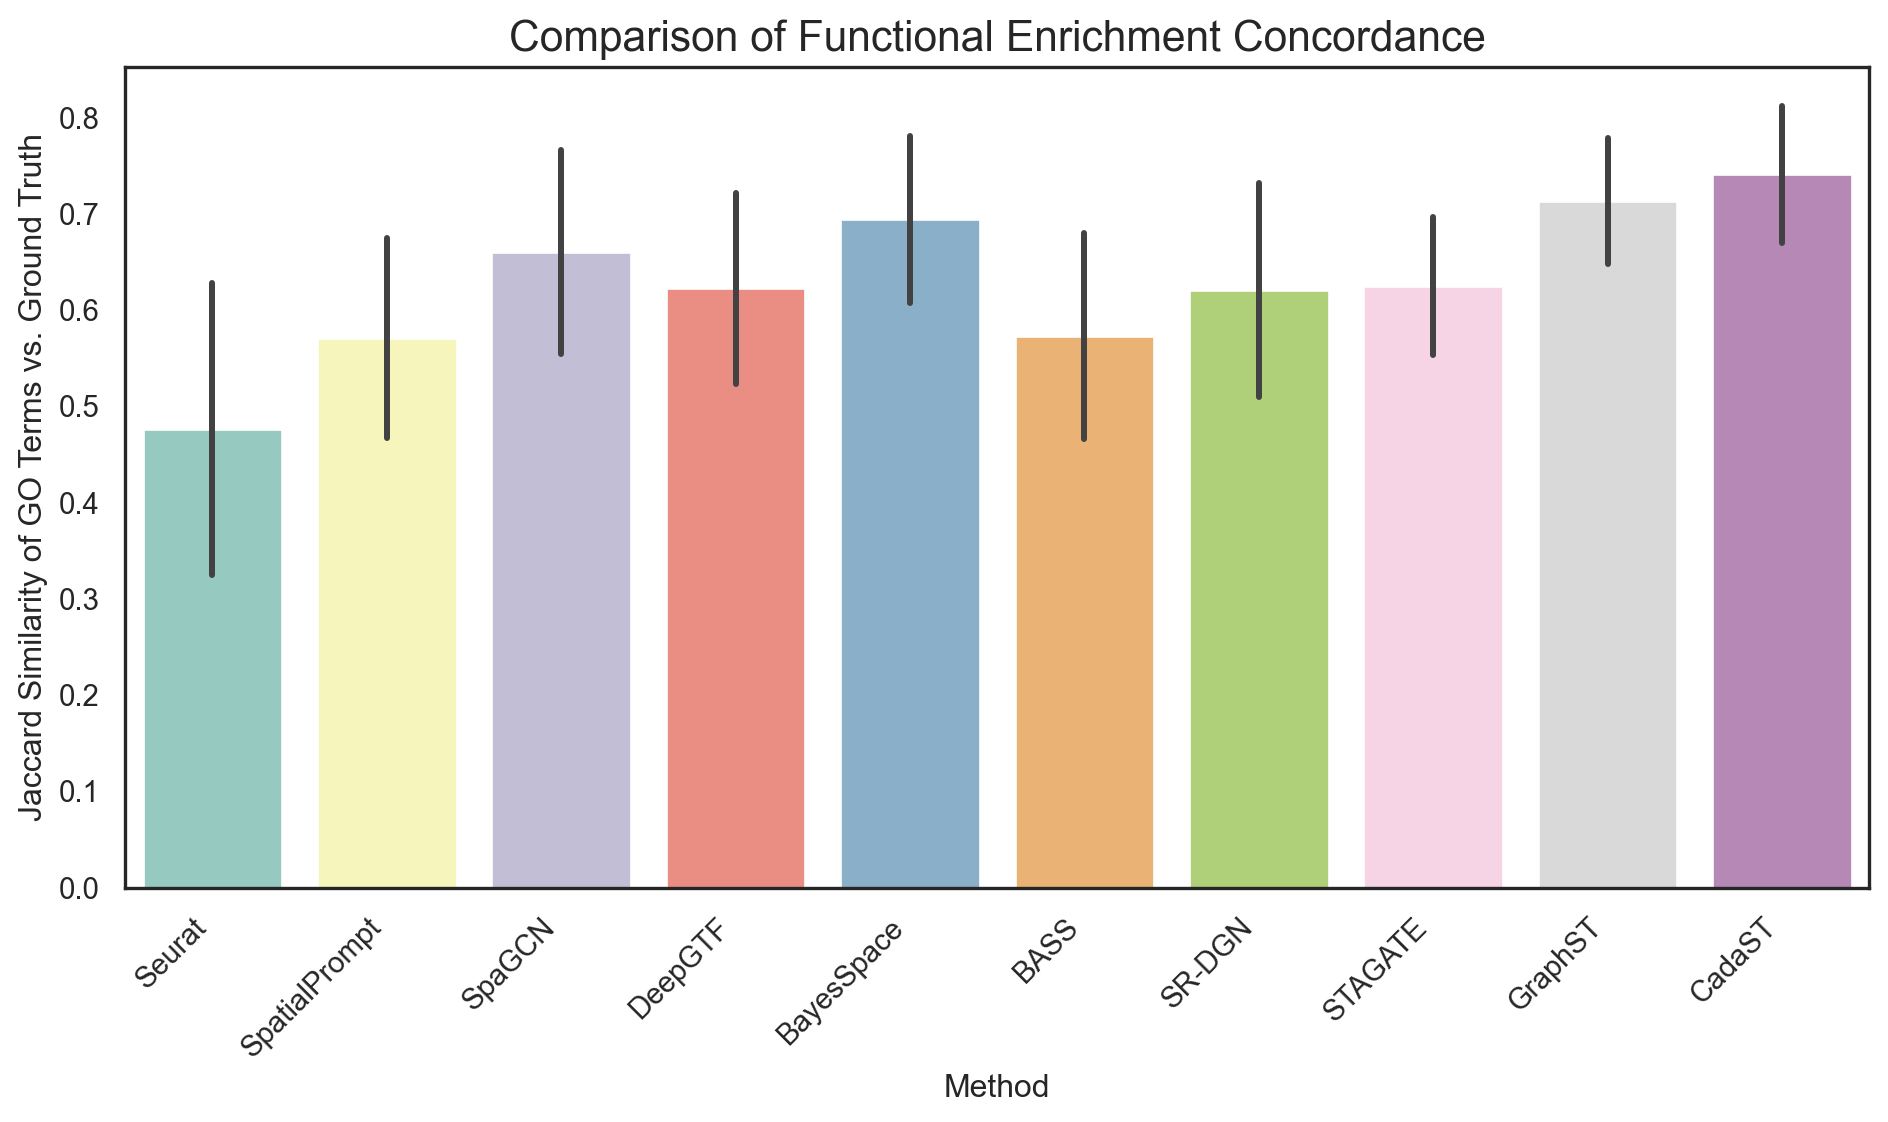

In [17]:
plt.figure(figsize=(10, 6))
plt_data = results_df[["Method", "Go Term Jaccard"]]
plt_data = plt_data.explode("Go Term Jaccard")
sns.barplot(data=plt_data, x="Method", y="Go Term Jaccard", palette="Set3", errorbar="se")
plt.title("Comparison of Functional Enrichment Concordance", fontsize=16)
plt.ylabel("Jaccard Similarity of GO Terms vs. Ground Truth", fontsize=12)
plt.xlabel("Method", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("go_term_jaccard_comparison.pdf", dpi=300, bbox_inches='tight')


In [12]:
def get_mean_jac(method_1, method_2, term="marker_genes"):
    mapping = map_clusters(adata, method_1, method_2)
    scores = [] 
    for cluster_1, cluster_2 in mapping.items():
        genes_1 = set(evaluation_artifacts[method_1][term][str(cluster_1)])
        genes_2 = set(evaluation_artifacts[method_2][term][str(cluster_2)])
        jac_score = jaccard_similarity(genes_1, genes_2)
        scores.append(jac_score)
    return np.mean(scores) if scores else 0.0
    
    
methods = ["Annotation"] + baselines
jac = np.zeros((len(methods), len(methods)))
for j, method_2 in enumerate(methods):
    for i, method_1 in enumerate(methods):
        if i == j:
            jac[i, j] = 1.0
        elif i > j:
            jac[i, j] = get_mean_jac(method_1, method_2, term="marker_genes")
        else :
            jac[i, j] = jac[j, i]

jac_df = pd.DataFrame(jac, index=methods, columns=methods)
jac_df 

,Annotation,Seurat,SpatialPrompt,SpaGCN,DeepGTF,BayesSpace,BASS,SR-DGN,STAGATE,GraphST,CadaST
Annotation,1.000000,0.413722,0.418247,0.497695,0.493953,0.555504,0.476535,0.509659,0.522188,0.589386,0.601623
Seurat,0.413722,1.000000,0.394195,0.413078,0.342396,0.416848,0.397614,0.429489,0.408565,0.361176,0.376304
SpatialPrompt,0.418247,0.394195,1.000000,0.501180,0.433108,0.521235,0.449932,0.479932,0.446318,0.466825,0.435406
SpaGCN,0.497695,0.413078,0.501180,1.000000,0.485040,0.591333,0.530513,0.598117,0.528669,0.514908,0.539651
DeepGTF,0.493953,0.342396,0.433108,0.485040,1.000000,0.473713,0.405266,0.432626,0.529345,0.555675,0.548434
BayesSpace,0.555504,0.416848,0.521235,0.591333,0.473713,1.000000,0.652137,0.587861,0.645115,0.614740,0.650392
BASS,0.476535,0.397614,0.449932,0.530513,0.405266,0.652137,1.000000,0.524274,0.587065,0.616156,0.584762
SR-DGN,0.509659,0.429489,0.479932,0.598117,0.432626,0.587861,0.524274,1.000000,0.650867,0.602074,0.622418
STAGATE,0.522188,0.408565,0.446318,0.528669,0.529345,0.645115,0.587065,0.650867,1.000000,0.634113,0.732929
GraphST,0.589386,0.361176,0.466825,0.514908,0.555675,0.614740,0.616156,0.602074,0.634113,1.000000,0.752424


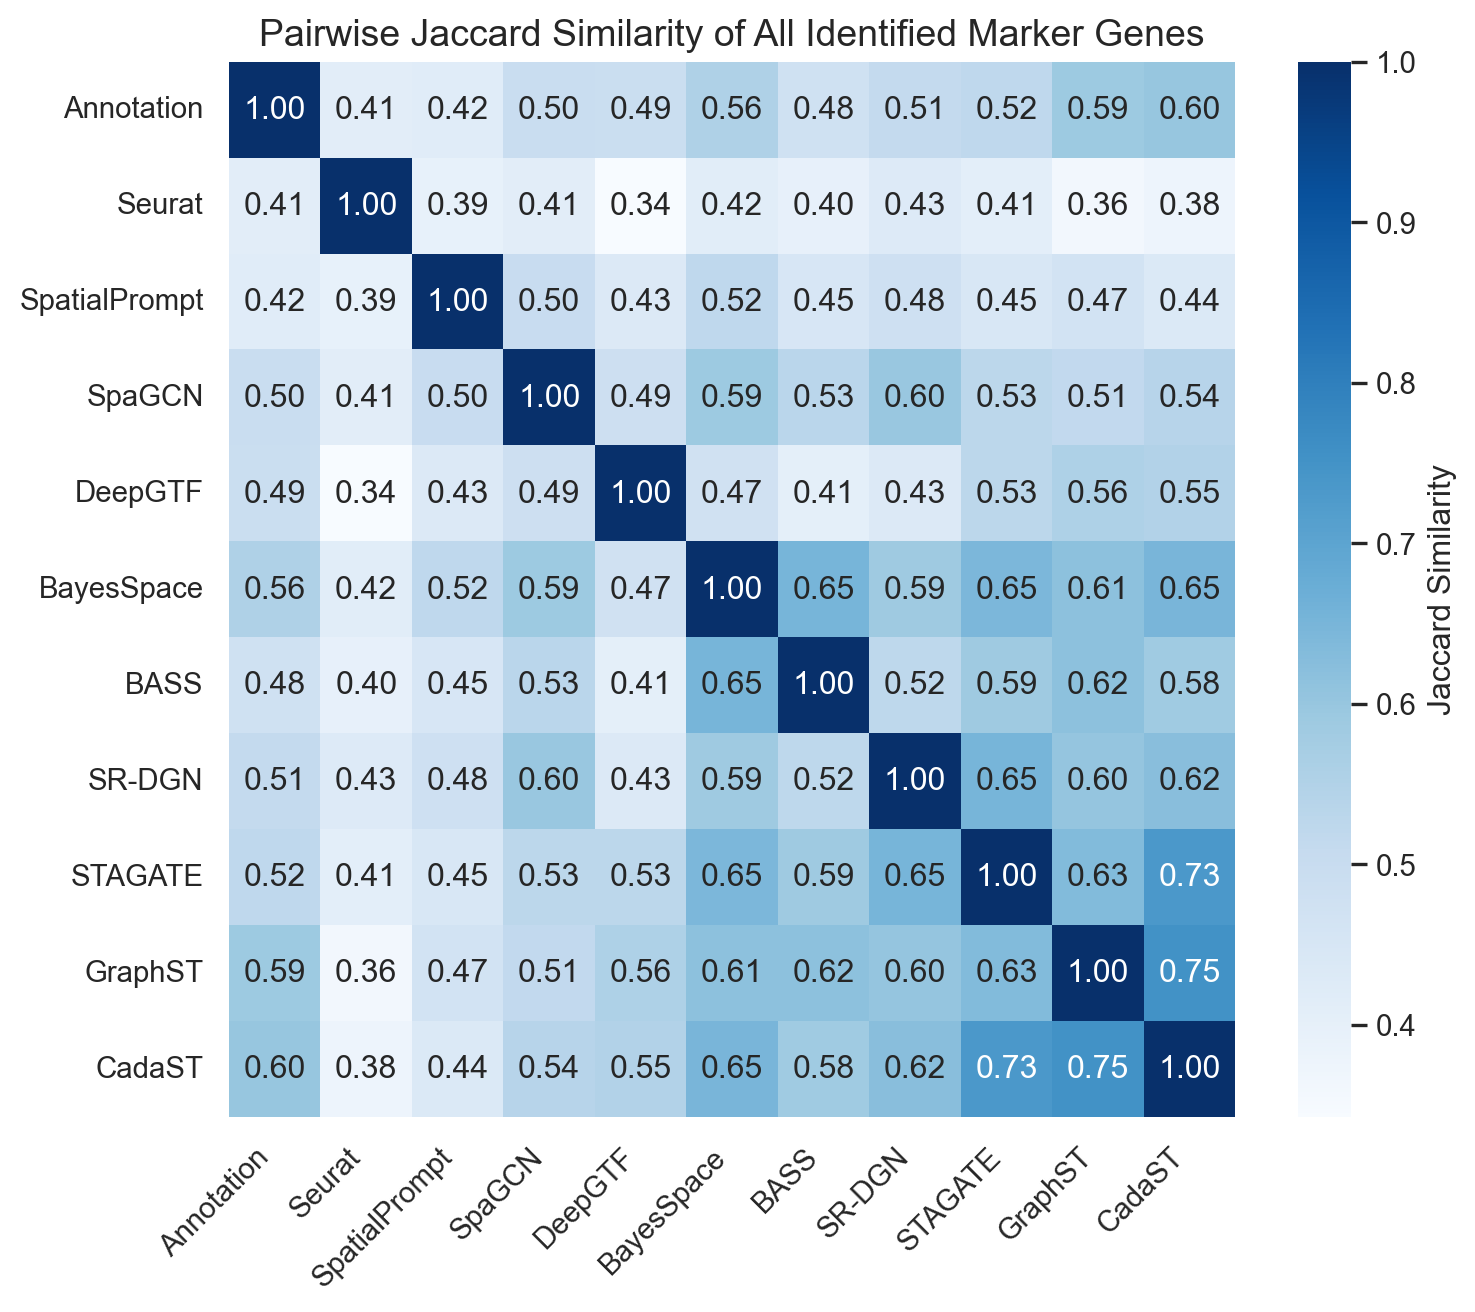

In [18]:
plt.figure(figsize=(8, 7))
sns.heatmap(jac_df, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "Jaccard Similarity"})
plt.title("Pairwise Jaccard Similarity of All Identified Marker Genes", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("marker_gene_jaccard_heatmap.pdf", dpi=300, bbox_inches='tight')

In [14]:
jac_go = np.zeros((len(methods), len(methods)))
for j, method_2 in enumerate(methods):
    for i, method_1 in enumerate(methods):
        if i == j:
            jac_go[i, j] = 1.0
        elif i > j:
            jac_go[i, j] = get_mean_jac(method_1, method_2, term="go_terms")
        else :
            jac_go[i, j] = jac_go[j, i]
jac_go_df = pd.DataFrame(jac_go, index=methods, columns=methods)
jac_go_df

,Annotation,Seurat,SpatialPrompt,SpaGCN,DeepGTF,BayesSpace,BASS,SR-DGN,STAGATE,GraphST,CadaST
Annotation,1.000000,0.476116,0.571074,0.660026,0.622364,0.694089,0.572792,0.620987,0.624732,0.713383,0.741001
Seurat,0.476116,1.000000,0.574316,0.537205,0.492010,0.569857,0.512395,0.541900,0.585060,0.526574,0.534540
SpatialPrompt,0.571074,0.574316,1.000000,0.651829,0.593126,0.691595,0.576400,0.625496,0.625268,0.658833,0.635598
SpaGCN,0.660026,0.537205,0.651829,1.000000,0.649727,0.714836,0.605443,0.710909,0.649344,0.669010,0.691384
DeepGTF,0.622364,0.492010,0.593126,0.649727,1.000000,0.622520,0.501129,0.563489,0.616203,0.665555,0.666764
BayesSpace,0.694089,0.569857,0.691595,0.714836,0.622520,1.000000,0.696677,0.691583,0.748754,0.768523,0.806585
BASS,0.572792,0.512395,0.576400,0.605443,0.501129,0.696677,1.000000,0.597061,0.693706,0.744185,0.715083
SR-DGN,0.620987,0.541900,0.625496,0.710909,0.563489,0.691583,0.597061,1.000000,0.736623,0.724284,0.747955
STAGATE,0.624732,0.585060,0.625268,0.649344,0.616203,0.748754,0.693706,0.736623,1.000000,0.735358,0.802451
GraphST,0.713383,0.526574,0.658833,0.669010,0.665555,0.768523,0.744185,0.724284,0.735358,1.000000,0.839333


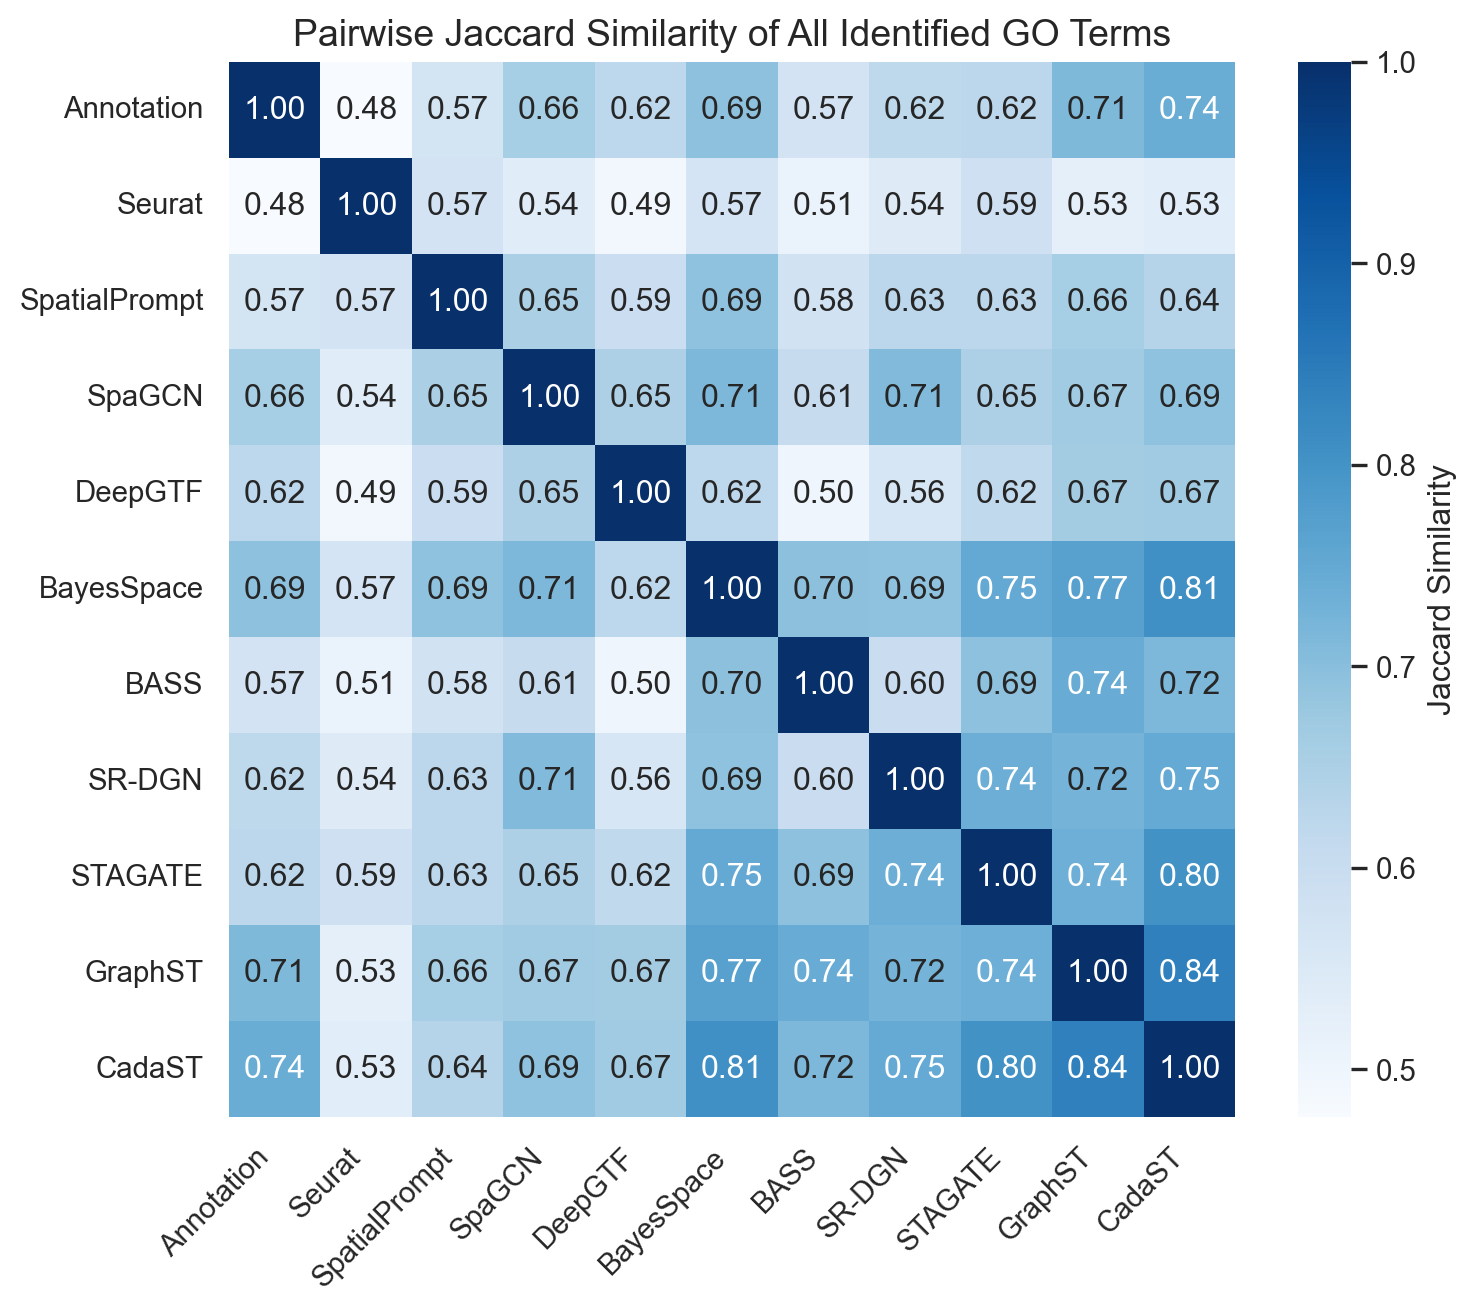

In [19]:
jac_go_df = pd.DataFrame(jac_go, index=methods, columns=methods)
plt.figure(figsize=(8, 7))
sns.heatmap(jac_go_df, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "Jaccard Similarity"})
plt.title("Pairwise Jaccard Similarity of All Identified GO Terms", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("go_term_jaccard_heatmap.pdf", dpi=300, bbox_inches='tight')